# First-stage feature distributions by class

This notebook plots one combined set of violin distributions for every annotated cell listed in the first-stage train, validation, and test splits. Matrix values are loaded directly from `Data/Raw/beach_all`.

Features: `r` = red, `g` = green, `b` = blue, `s` = slope, and `d` = elevation. NaN, infinite, and exact `-999` values are treated as missing and excluded from the violin distributions. Each violin includes the class mean and one standard deviation error bars. No pixel sampling cap is applied.

In [8]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (
    (PROJECT_ROOT / "Source").exists()
    or (PROJECT_ROOT / "Data").exists()
    or (PROJECT_ROOT / "pmaciag-volume-beach").exists()
):
    PROJECT_ROOT = PROJECT_ROOT.parent
if (PROJECT_ROOT / "pmaciag-volume-beach").exists():
    PROJECT_ROOT = PROJECT_ROOT / "pmaciag-volume-beach"
if not ((PROJECT_ROOT / "Source").exists() or (PROJECT_ROOT / "Data").exists()):
    raise RuntimeError("Could not locate pmaciag-volume-beach project directory.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Source.beach_dataset import (
    FEATURE_SUFFIXES,
    load_cell_array,
    make_class_mapping,
    read_class_name_mapping,
    read_split_csv,
)

In [9]:
CELL_DATA_ROOT = PROJECT_ROOT / "Data" / "Raw" / "beach_all"
CLASS_MAPPING_PATH = PROJECT_ROOT / "Data" / "Raw" / "Classes.xlsx"
SPLIT_PATH = PROJECT_ROOT / "Data" / "Preprocessed" / "dataset_splits.csv"

FEATURE_LABELS = {
    "r": "red channel (r)",
    "g": "green channel (g)",
    "b": "blue channel (b)",
    "s": "slope (s)",
    "d": "elevation (d)",
}
FEATURE_COLORS = {
    "r": "#d62728",
    "g": "#2ca02c",
    "b": "#1f77b4",
    "s": "#9467bd",
    "d": "#ff7f0e",
}
EXPECTED_SPLITS = {"train", "validation", "test"}

print(f"Cell data: {CELL_DATA_ROOT}")
print(f"Split file: {SPLIT_PATH}")

Cell data: /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/pmaciag-volume-beach/Data/Raw/beach_all
Split file: /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/pmaciag-volume-beach/Data/Preprocessed/dataset_splits.csv


In [10]:
if not CELL_DATA_ROOT.exists():
    raise FileNotFoundError(f"Cell data directory not found: {CELL_DATA_ROOT}")

all_labeled_data = read_split_csv(SPLIT_PATH)
if "split" not in all_labeled_data.columns:
    raise ValueError(f"Split column is missing from {SPLIT_PATH}")
actual_splits = set(all_labeled_data["split"].astype(str))
if actual_splits != EXPECTED_SPLITS:
    raise ValueError(f"Expected splits {sorted(EXPECTED_SPLITS)}, got {sorted(actual_splits)}")
if all_labeled_data.duplicated(["date", "cell_id"]).any():
    raise ValueError("Duplicate date/cell_id entries found in the combined split file.")

class_to_idx = make_class_mapping(all_labeled_data)
class_name_by_code = read_class_name_mapping(CLASS_MAPPING_PATH, class_to_idx.keys())
class_codes = [code for code, _ in sorted(class_to_idx.items(), key=lambda item: item[1])]
class_labels = [
    f"{code}: {class_name_by_code.get(code, f'class_{code}')}"
    for code in class_codes
]
display(all_labeled_data.groupby("split").size().rename("cells").to_frame())
display(all_labeled_data.groupby("class").size().rename("cells").to_frame())

,cells
split,
test,1219
train,5685
validation,1218


,cells
class,
0,117
1,2385
2,1447
3,665
4,706
5,645
6,536
7,856
8,723


In [11]:
def collect_feature_values(frame):
    buckets = {
        feature: {class_code: [] for class_code in class_codes}
        for feature in FEATURE_SUFFIXES
    }
    missing_cells = 0
    missing_values_by_feature = {feature: 0 for feature in FEATURE_SUFFIXES}
    rows = frame[["date", "cell_id", "class"]].itertuples(index=False, name=None)
    for date, cell_id, class_code in tqdm(rows, total=len(frame), desc="Loading labeled cells"):
        array = load_cell_array(CELL_DATA_ROOT, date, cell_id, FEATURE_SUFFIXES)
        missing_mask = ~np.isfinite(array)
        if missing_mask.any():
            missing_cells += 1
        class_code = str(class_code)
        for feature_index, feature in enumerate(FEATURE_SUFFIXES):
            values = array[feature_index].reshape(-1)
            finite_mask = np.isfinite(values)
            missing_values_by_feature[feature] += int((~finite_mask).sum())
            buckets[feature][class_code].extend(values[finite_mask].astype(float).tolist())
    missing_summary = {
        "cells": missing_cells,
        "values": sum(missing_values_by_feature.values()),
        "by_feature": missing_values_by_feature,
    }
    return buckets, missing_summary


def plot_combined_violins(buckets):
    fig, axes = plt.subplots(
        nrows=len(FEATURE_SUFFIXES),
        ncols=1,
        figsize=(max(12, len(class_codes) * 1.2), 3.2 * len(FEATURE_SUFFIXES)),
        sharex=True,
    )
    positions = np.arange(1, len(class_codes) + 1)
    for axis, feature in zip(axes, FEATURE_SUFFIXES):
        data = [buckets[feature][class_code] for class_code in class_codes]
        nonempty = [(position, values) for position, values in zip(positions, data) if values]
        if nonempty:
            nonempty_positions = [position for position, _ in nonempty]
            nonempty_data = [values for _, values in nonempty]
            parts = axis.violinplot(
                nonempty_data,
                positions=nonempty_positions,
                showmeans=False,
                showmedians=True,
                showextrema=False,
            )
            for body in parts["bodies"]:
                body.set_facecolor(FEATURE_COLORS[feature])
                body.set_edgecolor("black")
                body.set_alpha(0.65)
            means = np.array([np.mean(values) for values in nonempty_data])
            standard_deviations = np.array([np.std(values) for values in nonempty_data])
            axis.errorbar(
                nonempty_positions,
                means,
                yerr=standard_deviations,
                fmt="o",
                color="black",
                ecolor="black",
                elinewidth=1.1,
                capsize=3,
                markersize=4,
            )
            if "cmedians" in parts:
                parts["cmedians"].set_color("black")
        axis.set_title(FEATURE_LABELS[feature])
        axis.grid(axis="y", alpha=0.25)

    axes[-1].set_xticks(positions)
    axes[-1].set_xticklabels(class_labels, rotation=45, ha="right")
    axes[-1].set_xlabel("Class")
    fig.suptitle(
        "Feature distributions by class and channel\n"
        "Missing values excluded; bars show mean +/- 1 std",
        y=1.01,
    )
    fig.tight_layout()
    return fig

Loading labeled cells: 100%|██████████| 8122/8122 [00:14<00:00, 562.46it/s]


Annotated cells with missing values: 65
Missing pixel-channel values: 10,134


,feature,missing_values
0,r,0
1,g,0
2,b,0
3,s,5074
4,d,5060


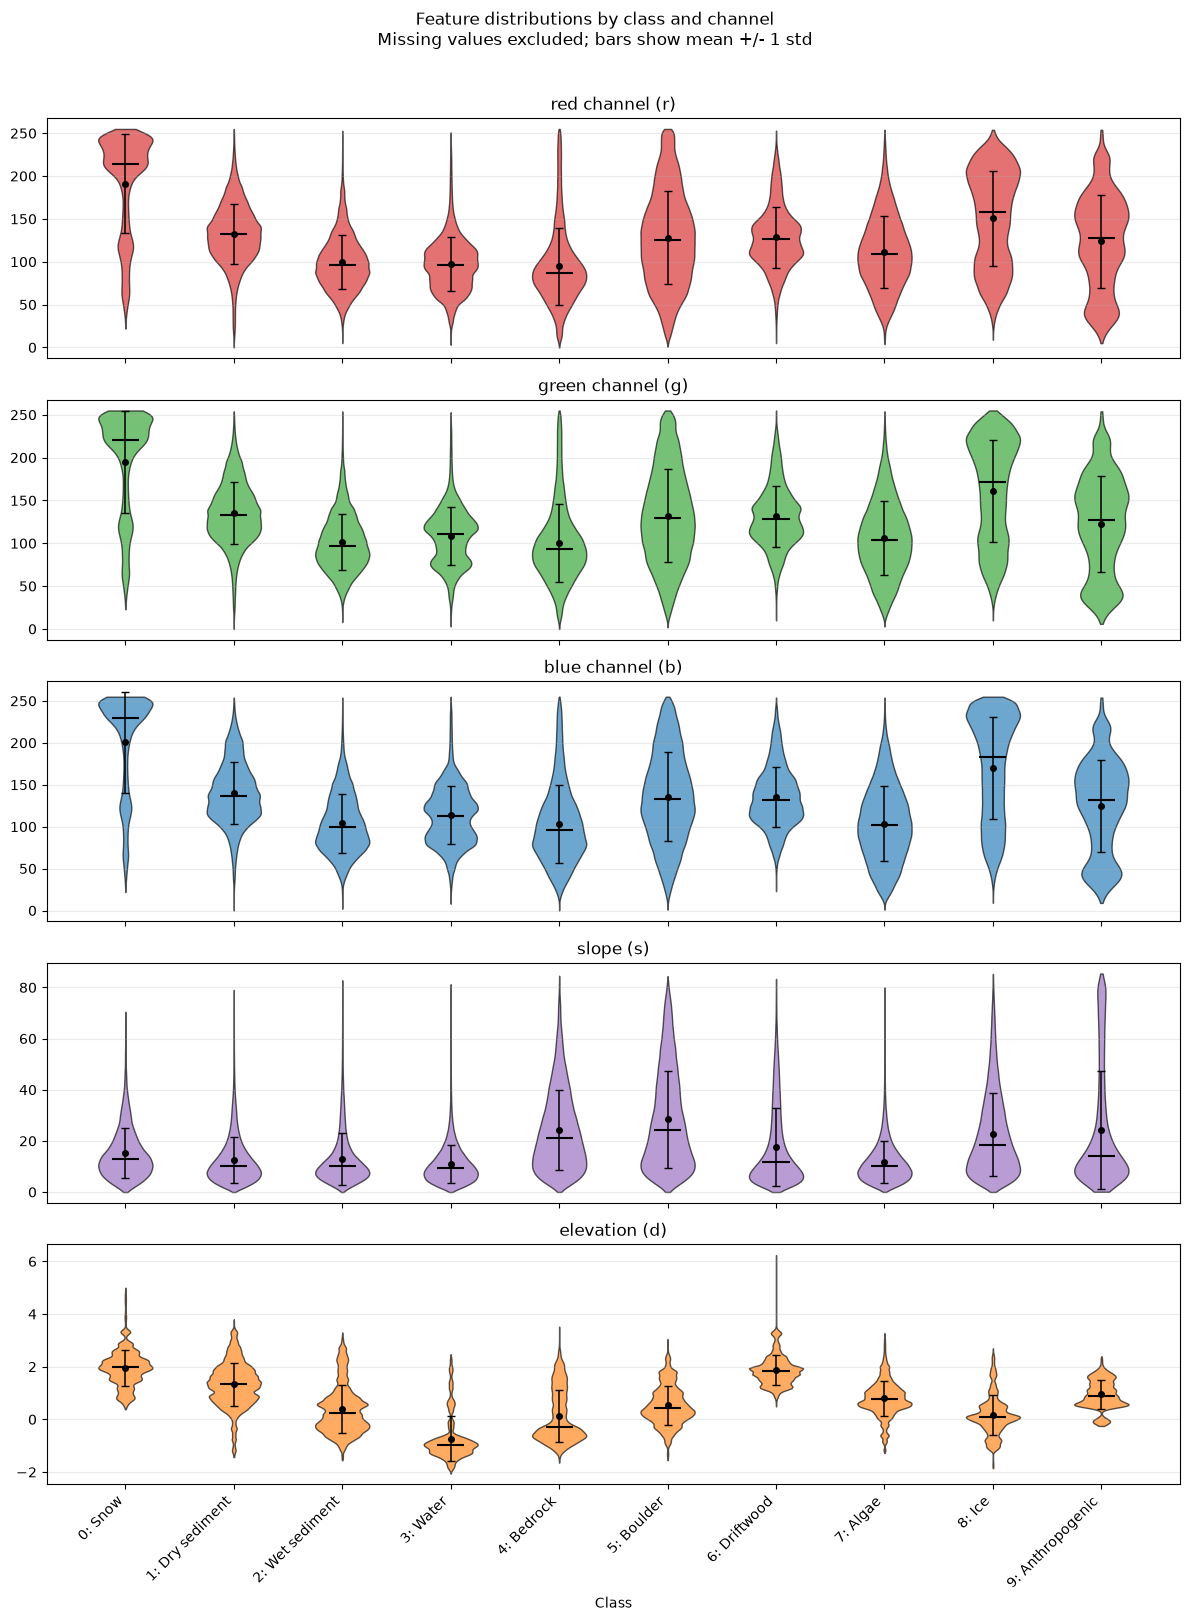

In [12]:
combined_buckets, missing_summary = collect_feature_values(all_labeled_data)
print(f"Annotated cells with missing values: {missing_summary['cells']:,}")
print(f"Missing pixel-channel values: {missing_summary['values']:,}")
display(
    pd.DataFrame({
        "feature": FEATURE_SUFFIXES,
        "missing_values": [missing_summary["by_feature"][feature] for feature in FEATURE_SUFFIXES],
    })
)
combined_figure = plot_combined_violins(combined_buckets)
plt.show()

In [13]:
OUTLIER_THRESHOLD = -900

# Exact -999 values are converted to NaN by load_cell_array and excluded from
# the violin plot. This report finds remaining finite values near -1000.
outlier_rows = []
rows = all_labeled_data[["split", "date", "cell_id", "class"]].itertuples(
    index=False,
    name=None,
)
for split, date, cell_id, class_code in tqdm(
    rows,
    total=len(all_labeled_data),
    desc="Checking slope/elevation outliers",
):
    array = load_cell_array(CELL_DATA_ROOT, date, cell_id, FEATURE_SUFFIXES)
    slope = array[FEATURE_SUFFIXES.index("s")]
    elevation = array[FEATURE_SUFFIXES.index("d")]
    slope_pixels = int((np.isfinite(slope) & (slope <= OUTLIER_THRESHOLD)).sum())
    elevation_pixels = int((np.isfinite(elevation) & (elevation <= OUTLIER_THRESHOLD)).sum())
    if slope_pixels or elevation_pixels:
        class_code = str(class_code)
        outlier_rows.append({
            "split": split,
            "date": date,
            "cell_id": cell_id,
            "class": class_code,
            "class_name": class_name_by_code.get(class_code, f"class_{class_code}"),
            "slope_outlier_pixels": slope_pixels,
            "elevation_outlier_pixels": elevation_pixels,
            "total_outlier_pixels": slope_pixels + elevation_pixels,
        })

outlier_cells = pd.DataFrame(outlier_rows)
slope_total = int(outlier_cells["slope_outlier_pixels"].sum()) if not outlier_cells.empty else 0
elevation_total = int(outlier_cells["elevation_outlier_pixels"].sum()) if not outlier_cells.empty else 0
print(f"Outlier threshold: <= {OUTLIER_THRESHOLD}")
print(f"Cells with slope/elevation outliers: {len(outlier_cells):,}")
print(f"Slope outlier pixels: {slope_total:,}")
print(f"Elevation outlier pixels: {elevation_total:,}")
print(f"Total outlier pixels: {slope_total + elevation_total:,}")
if not outlier_cells.empty:
    display(outlier_cells.sort_values(["date", "cell_id"]).reset_index(drop=True))
    print("Cell IDs:")
    print(", ".join(outlier_cells["cell_id"].astype(str).tolist()))

Checking slope/elevation outliers: 100%|██████████| 8122/8122 [00:10<00:00, 801.61it/s]

Outlier threshold: <= -900
Cells with slope/elevation outliers: 0
Slope outlier pixels: 0
Elevation outlier pixels: 0
Total outlier pixels: 0


In [7]:
from concurrent.futures import ThreadPoolExecutor

FULL_DATASET_SCAN_WORKERS = 4
FULL_DATASET_SCAN_BATCH_SIZE = 1000


def discover_complete_cell_ids(date_dir):
    cell_ids = []
    incomplete_cells = 0
    for red_path in date_dir.glob("*r.txt"):
        cell_id = red_path.name[:-len("r.txt")]
        if all((date_dir / f"{cell_id}{feature}.txt").is_file() for feature in FEATURE_SUFFIXES):
            cell_ids.append(cell_id)
        else:
            incomplete_cells += 1
    return cell_ids, incomplete_cells


def cell_contains_missing_values(date_dir, cell_id):
    array = load_cell_array(CELL_DATA_ROOT, date_dir.name, cell_id, FEATURE_SUFFIXES)
    return bool((~np.isfinite(array)).any())


date_directories = sorted(path for path in CELL_DATA_ROOT.iterdir() if path.is_dir())
total_complete_cells = 0
total_incomplete_cells = 0
total_cells_with_missing_values = 0

with ThreadPoolExecutor(max_workers=FULL_DATASET_SCAN_WORKERS) as executor:
    for date_index, date_dir in enumerate(date_directories, start=1):
        cell_ids, incomplete_cells = discover_complete_cell_ids(date_dir)
        date_missing_cells = 0
        progress = tqdm(
            total=len(cell_ids),
            desc=f"Scanning {date_dir.name} ({date_index}/{len(date_directories)})",
        )
        for batch_start in range(0, len(cell_ids), FULL_DATASET_SCAN_BATCH_SIZE):
            batch = cell_ids[batch_start:batch_start + FULL_DATASET_SCAN_BATCH_SIZE]
            missing_flags = executor.map(
                lambda cell_id: cell_contains_missing_values(date_dir, cell_id),
                batch,
            )
            date_missing_cells += sum(missing_flags)
            progress.update(len(batch))
        progress.close()

        total_complete_cells += len(cell_ids)
        total_incomplete_cells += incomplete_cells
        total_cells_with_missing_values += date_missing_cells
        print(
            f"{date_dir.name}: {date_missing_cells:,} of {len(cell_ids):,} complete cells "
            "contain missing values"
        )

print(f"Complete cells scanned in the entire dataset: {total_complete_cells:,}")
print(f"Incomplete cells skipped: {total_incomplete_cells:,}")
print(
    "Cells with missing values in the entire dataset: "
    f"{total_cells_with_missing_values:,}"
)

Scanning 20180722 (1/15): 100%|██████████| 46483/46483 [00:30<00:00, 1528.91it/s]


20180722: 94 of 46,483 complete cells contain missing values


Scanning 20180731 (2/15): 100%|██████████| 54304/54304 [00:38<00:00, 1399.86it/s]


20180731: 44 of 54,304 complete cells contain missing values


Scanning 20180812 (3/15): 100%|██████████| 67022/67022 [00:35<00:00, 1901.48it/s]


...

20230807: 117 of 9,506 complete cells contain missing values


Scanning 20240623 (14/15): 100%|██████████| 72043/72043 [00:37<00:00, 1936.57it/s]


20240623: 73 of 72,043 complete cells contain missing values


Scanning 20240806 (15/15): 100%|██████████| 58149/58149 [00:31<00:00, 1860.89it/s]

20240806: 3,507 of 58,149 complete cells contain missing values
Complete cells scanned in the entire dataset: 805,671
Incomplete cells skipped: 0
Cells with missing values in the entire dataset: 4,620
